# Junta: asistencia marginal no garantiza disponibilidad de quórum

## Resumen
En el caso sintético, independencia de marginales predice0,8512sin reservas yparece cumplir meta0,85; mezcla exacta conausencia común da0,76. Dos participantes dereserva autorizados elevan disponibilidad a0,9139concoste2. No se mide calidad de votos ni aprobación.

## Modelo ycondiciones
Comitébase4, quórumfijo3 ypresencia obligatoria del miembro0(risk_lead). Régimen normalpeso0,8: asistencia(0,95;1;1;1). Disrupción compartidapeso0,2: (0,95;0;0;0). Dentro de cada régimen se asume independencia; incondicionalmente los3miembros comparten ausencia. Reservas autorizadas tienenprobabilidad0,9ysonindependientesdelrégimen por supuesto.

Se enumeran máscarasX∈{0,1}^N ycalculaΣr w_rΣX I(sumX≥3,X0=1)Πi p_ri^Xi(1−p_ri)^(1−Xi). El baseline reemplaza la mezcla porproducto de marginales. Objetivo: menorcoste de reservas que alcanza meta, manteniendo quórum3yrolobligatorio. No se autorizan sustituciones reales por elmodelo.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'regimes': [{'name': 'normal', 'weight': 0.8, 'attendance': [0.95, 1, 1, 1]},
  {'name': 'shared_disruption', 'weight': 0.2, 'attendance': [0.95, 0, 0, 0]}],
 'members': ['risk_lead', 'member_A', 'member_B', 'member_C'],
 'quorum': 3,
 'mandatory': [0],
 'standby_menu': [0, 1, 2],
 'standby_attendance': 0.9,
 'unit_standby_cost': 1,
 'target': 0.85,
 'units': 'synthetic availability probability per scheduled session; unit cost arbitrary; authorized extra participants count toward fixed quorum by assumption',
 'hypothesis': 'marginal independence can falsely pass target0.85; exact regime-aware plan reaches target with minimum authorized standbys'}

## Planes ybaseline
Mismas probabilidades marginales, diferente distribución conjunta. Las224filas de máscaras para0/1/2reservas se guardan sin selección, incluidas masas0para conservar elespacio completo.

,standbys,cost,exact_availability,independent_marginal,states
0,0,0,0.7600,0.85120,32
1,1,1,0.7600,0.93328,64
2,2,2,0.9139,0.94764,128


{'selected_exact': {'standbys': 2, 'cost': 2, 'availability': 0.9139},
 'baseline_independent': {'standbys': 0,
  'cost': 0,
  'availability': 0.8512000000000001},
 'actual_baseline_availability': 0.76,
 'independence_error': 0.09120000000000006,
 'seconds': 0.003220350999981747,
 'python_peak_bytes': 32841,
 'python': '3.12.14',
 'platform': 'Linux-6.18.57-x86_64-with-glibc2.39'}

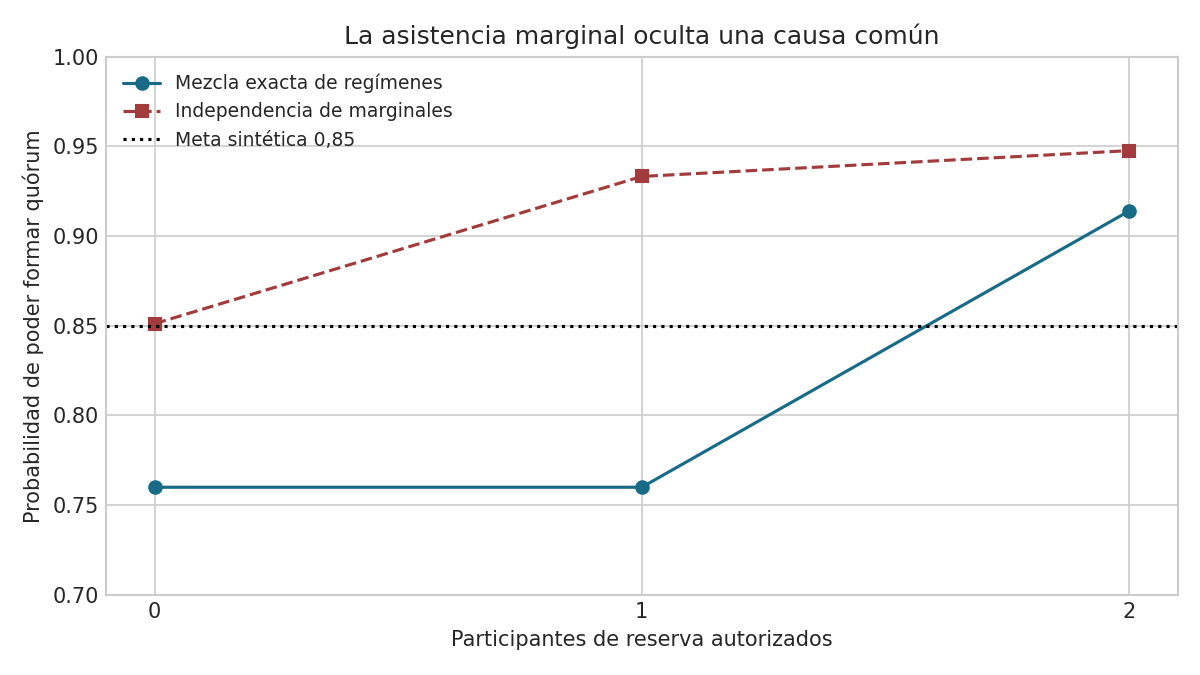

In [2]:
display(pd.read_csv('results/plans.csv').round(5))
display(summary)
display(Image(filename='results/quorum.png'))

## Falsación ylímites
La independencia no falla siempre hacia elmismo lado. Aquí da un falso pase. Elrolobligatorio conprobabilidad0,95limita toda disponibilidad a≤0,95; meta0,97es imposible. Si sube disrupción a0,8, dosreservas tampoco cumplen. Si quórum se eleva a4, no basta este menú. No se baja quórum para forzar factibilidad.

In [3]:
display(pd.read_csv('results/sensitivity.csv'))
display(pd.read_csv('results/scaling.csv'))
assert summary['baseline_independent']['availability']>=cfg['target']>summary['actual_baseline_availability']
assert summary['selected_exact']['availability']>=cfg['target']

,disruption_weight,feasible,standbys,cost,availability
0,0.1,True,0.0,0.0,0.8550
1,0.2,True,2.0,2.0,0.9139
2,0.4,True,2.0,2.0,0.8778
3,0.8,False,NaN,NaN,NaN


,members,states,median_seconds,repetitions
0,4,32,0.000045,5
1,6,128,0.000202,5
2,8,512,0.000967,5


## Decisión
Continuar solo como prueba de resiliencia con2reservas elegibles si reglas vigentes ysupuestos lo permiten. Ajustar calendario/modos remotos si haycorrelación de ausencias. Detener propuesta cuando menú no alcanza meta. No asesoría legal, cambio de estatutos, evidencia de calidad decisional ni probabilidad de aprobación. ComponenteS2 sintético, programa21S1sinrecertificar.

# Iteración 30: investigar el supuesto pendiente del 29

## Pregunta de continuidad
El 29 se fijó asistencia 0,9 de cada reserva en todos los regímenes y se asumió independencia condicional. Su roadmap pidió que las reservas también sufran la disrupción. Hoy conservamos evento, miembros, quórum y rol obligatorio, pero permitimos marginales diferentes durante disrupción y dependencia arbitraria **entre dos reservas**.

Separamos las ablations: recuperar 29 (q=0,9), degradar marginales a 0,7 y después cambiar la distribución conjunta manteniendo esas marginales.

**Antes de calcular:** si ambas reservas asisten con probabilidad 70%, ¿sabemos la probabilidad de que estén las dos? Multiplicar 0,7 por 0,7 exige independencia. Intente construir una tabla 2×2 con esas mismas marginales y otro valor de la celda 11.

## 1. Reducir el modelo original sin cambiar el evento
Sean $Z$ el régimen, $R$ la presencia del responsable de riesgo y $B_1,B_2$ las reservas. El evento sigue siendo
$$E=\{R=1,\ \text{asistentes}\ge3\}.$$
En normal, los tres miembros principales están presentes: solo falta $R$. En disrupción, los tres faltan y se necesitan simultáneamente $R,B_1,B_2$.

Escriba $s=P(Z=\text{disrupción})$ y $r=P(R=1\mid Z)$ constante. Se **mantiene** la independencia de $R$ respecto del par de reservas condicional al régimen. Por probabilidad total:
$$P(E)=(1-s)r+sr\,t=r[(1-s)+st],\qquad t=P(B_1=B_2=1\mid Z=\text{disrupción}).$$
El modelo 29 usaba $t=q_1q_2$. La propuesta sustituye ese supuesto puntual por todos los $t$ compatibles con las marginales, sin modificar el evento.

## 2. Derivar las cotas desde la tabla de estados
Fije $q_1=P(B_1=1\mid Z)$ y $q_2=P(B_2=1\mid Z)$. Si $p_{11}=t$, las otras celdas son
$$p_{10}=q_1-t,\quad p_{01}=q_2-t,\quad p_{00}=1-q_1-q_2+t.$$
Suman uno y reproducen las marginales. La no negatividad implica
$$\max(0,q_1+q_2-1)\le t\le\min(q_1,q_2).$$
Son cotas Fréchet–Hoeffding clásicas, no una fórmula nueva. Son **sharp**: las cuatro celdas construyen una distribución válida en cada extremo. La disponibilidad es lineal creciente en $t$, por lo que
$$L=r[(1-s)+s\max(0,q_1+q_2-1)],\quad U=r[(1-s)+s\min(q_1,q_2)].$$
El oracle LP de los tests minimiza/maximiza $p_{11}$ sujeto a suma uno, marginales y no negatividad, sin usar esta fórmula cerrada.

In [4]:
from src.reserve_ambiguity import ReservePlan, bounds, coupling, nominal_existing_engine
config30=json.loads(Path('config_dependence.json').read_text())
summary30=json.loads(Path('results/dependence_summary.json').read_text())
display(pd.read_csv('results/reserve_couplings.csv'))
p=ReservePlan('exercise',.7,.7,2)
b=bounds(p)
for key in ['lower_joint','independent_joint','upper_joint']:
    masses=coupling(p,b[key])
    assert abs(sum(masses)-1)<1e-12
    assert abs(masses[2]+masses[3]-.7)<1e-12
    assert abs(masses[1]+masses[3]-.7)<1e-12
display(b)

,case,state,probability,q1,q2
0,lower,0,0.00,0.7,0.7
1,lower,1,0.30,0.7,0.7
2,lower,10,0.30,0.7,0.7
3,lower,11,0.40,0.7,0.7
4,independent,0,0.09,0.7,0.7
5,independent,1,0.21,0.7,0.7
6,independent,10,0.21,0.7,0.7
7,independent,11,0.49,0.7,0.7
8,upper_positive,0,0.30,0.7,0.7
9,upper_positive,1,0.00,0.7,0.7


{'lower_joint': 0.3999999999999999,
 'independent_joint': 0.48999999999999994,
 'upper_joint': 0.7,
 'lower_availability': 0.836,
 'nominal_availability': 0.8531,
 'upper_availability': 0.893}

## 3. Separar cambios de marginales y dependencia
- Recuperar 29: q=0,9, nominal 0,9139 y lower 0,912.
- Degradar solo marginales: q=0,7, nominal 0,8531.
- Mismas marginales 0,7, peor dependencia: 0,836, por debajo de meta 0,85.
- Mismas marginales 0,7, dependencia positiva perfecta: 0,893, **mayor** que independencia.

¿Por qué la última mejora? En el régimen crítico se requieren ambas reservas (AND); asistencia conjunta positiva ayuda. No toda correlación empeora disponibilidad. La ausencia común del grupo principal y la dependencia dentro del par son objetos distintos.

,name,q1,q2,cost,lower_joint,independent_joint,upper_joint,lower_availability,nominal_availability,upper_availability,oct29_engine_nominal
0,availability_A,0.7,0.7,2,0.4,0.49,0.7,0.836,0.8531,0.893,0.8531
1,availability_B,0.8,0.8,3,0.6,0.64,0.8,0.874,0.8816,0.912,0.8816
2,availability_C,0.9,0.9,4,0.8,0.81,0.9,0.912,0.9139,0.931,0.9139


{'lower_joint': 0.8,
 'independent_joint': 0.81,
 'upper_joint': 0.9,
 'lower_availability': 0.912,
 'nominal_availability': 0.9139,
 'upper_availability': 0.931}

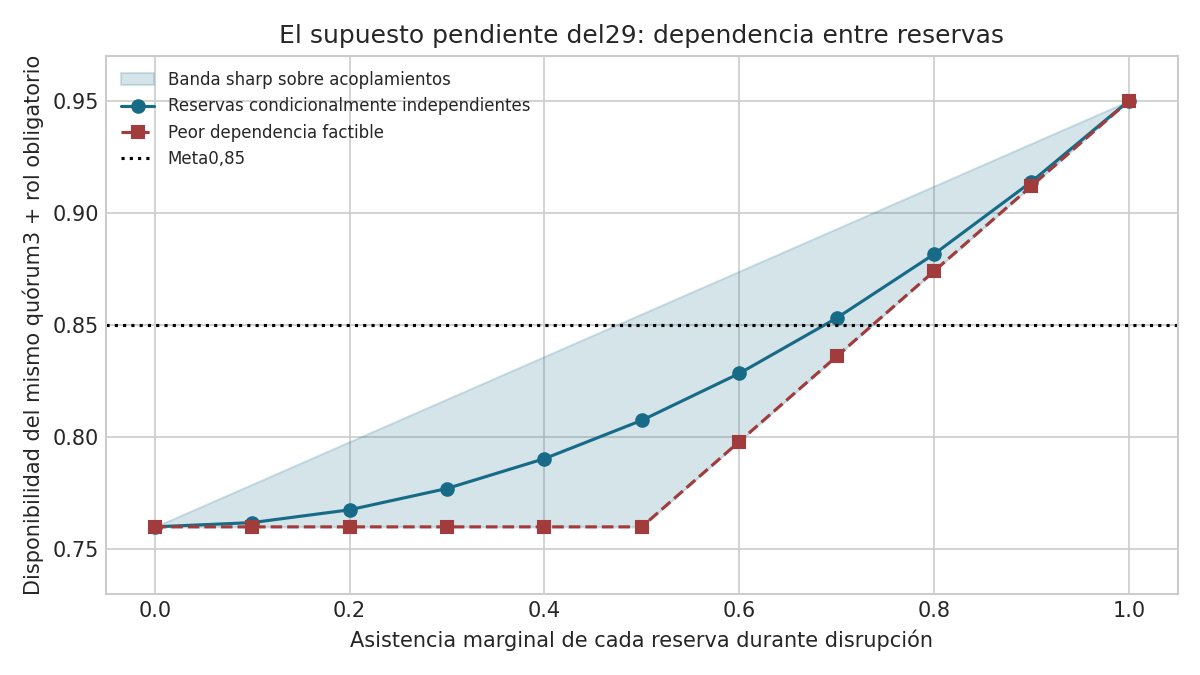

In [5]:
display(pd.read_csv('results/dependence_plans.csv').round(6))
display(summary30['original29_q09_bounds'])
for row in config30['plans']:
    plan=ReservePlan(**row)
    assert abs(nominal_existing_engine(plan)-bounds(plan)['nominal_availability'])<1e-12
display(Image(filename='results/dependence.png'))

## 4. Obtener una frontera de decisión
Para reservas simétricas $q_1=q_2=q$, defina
$$c=\frac{\tau/r-(1-s)}s.$$
Si $0<c\le1$, independencia exige $q^2\ge c$, mientras la garantía sharp exige $2q-1\ge c$:
$$q_{\mathrm{nom}}\ge\sqrt c,\qquad q_{\mathrm{rob}}\ge\frac{1+c}{2}.$$
Con $\tau=0,85$, $r=0,95$ y $s=0,2$: $q_{nom}=0,688247$ frente a $q_{rob}=0,736842$. Si $c\le0$, normal ya basta. Si $c>1$, ni reservas perfectas cubren la meta bajo estos supuestos.

El menú representa opciones hipotéticas, no probabilidades elegidas mágicamente: A(q=0,7,coste 2) pasa nominalmente; B(q=0,8,coste 3) es la mínima que cumple la cota robusta; C(q=0,9,coste 4) también cumple.

In [6]:
display(summary30)
assert summary30['nominal_choice']['name']=='availability_A'
assert summary30['nominal_choice']['nominal_availability']>=.85>summary30['nominal_choice']['lower_availability']
assert summary30['robust_choice']['name']=='availability_B'
assert summary30['robust_choice']['lower_availability']>=.85
display(pd.read_csv('results/dependence_scaling.csv'))

{'nominal_choice': {'name': 'availability_A',
  'cost': 2,
  'lower_availability': 0.836,
  'nominal_availability': 0.8531,
  'upper_availability': 0.893},
 'robust_choice': {'name': 'availability_B',
  'cost': 3,
  'lower_availability': 0.874,
  'nominal_availability': 0.8816,
  'upper_availability': 0.912},
 'critical_nominal_q': 0.6882472016116852,
 'critical_robust_q': 0.7368421052631577,
 'original29_q09_bounds': {'lower_joint': 0.8,
  'independent_joint': 0.81,
  'upper_joint': 0.9,
  'lower_availability': 0.912,
  'nominal_availability': 0.9139,
  'upper_availability': 0.931},
 'seconds': 0.00010108200001468504,
 'python_peak_bytes': 1160,
 'python': '3.12.14',
 'platform': 'Linux-6.18.57-x86_64-with-glibc2.39'}

,plans,median_seconds,repetitions
0,3,0.000004,5
1,30,0.000028,5
2,300,0.000404,5


## 5. Qué aprendemos y qué queda pendiente
La contribución es una **adaptación operativa de cotas conocidas** a la herramienta 29, con baseline recuperado y menú auditable. No es una copula nueva, probabilidad calibrada o eficacia de gobierno demostrada.

La garantía cubre solamente dependencia entre dos reservas durante disrupción, con marginales y modelo del rol obligatorio fijos. No cubre correlación del responsable de riesgo con reservas, error de marginales, estatutos o calidad de decisiones. El conjunto amplio puede ser conservador: evidencia de dependencia positiva podría estrecharlo.

Antes de una aplicación: justificar elegibilidad, medir marginales durante incidentes e identificar causas compartidas. Consulte matriz_prior_art.md, RESEARCH_LOG.md y ROADMAP.md para clasificación, negativos y pruebas siguientes.

## 31 octubre: ¿y si el rol obligatorio también depende de las reservas?
La pregunta central acumulativa es certificar disponibilidad, sin confundirla con calidad de gobierno. El30 relajamos solo la dependencia entre suplentes. Hoy contrastamos esa garantía contra la clase de todas las leyes conjuntas de $R,B_1,B_2$ con marginales conocidas. Son **cotas clásicas especializadas y auditoría de supuestos**, no nueva teoría de cópulas. La decisión original con meta0,85 se conserva; una frontera diseñada0,872 evidencia cuándo cambia. No es calibración empírica ni selección posterior presentada como confirmación.

### Notación, unidades y supuestos
$R,B_i\in\{0,1\}$ indican asistencia por sesión, $s\in[0,1]$ es peso de disrupción, $r=P(R=1\mid g)$ en ambos regímenes; $q_i=P(B_i=1\mid shock)$. Todos son adimensionales. Tres principales asisten en normal y ninguno en shock. Quórum fijo3 y presencia de Robligatoria. Por tanto $E=\{R=1\}$ en normal y $E=\{R=B_1=B_2=1\}$ en shock. Elegibilidad/autorización siguen supuestas. No datos de personas ni reglas jurídicas.

### Derivación: original → limitación → extensión
Original30: $L_{30}=r[1-s+s\max(0,q_1+q_2-1)]$, requiere $R\perp(B_1,B_2)\mid g$. Sin esa independencia no podemos multiplicar por$r$.

Sea $p_{abc}=P(R=a,B_1=b,B_2=c\mid shock)$. Las8masas cumplen $p\ge0$, $\sum p=1$, $\sum ap=r$, $\sum bp=q_1$, $\sum cp=q_2$. Minimizamos/maximizamos$p_{111}$; conjunto no vacío porque contiene producto independiente y compacto por simplex, así que existen extremos.

Por complemento y cota de unión: $P(RB_1B_2=1)=1-P(R=0\cup B_1=0\cup B_2=0)\ge r+q_1+q_2-2$; además es$\ge0$. La intersección está contenida en cada evento, de donde$p_{111}\le\min(r,q_1,q_2)$. Se alcanzan puntualmente ambos extremos al acomodar complementos disjuntos hasta cubrir el espacio, o eventos anidados para el máximo. No se afirma que la envolvente inferior sea una cópula multivariada global; solo que cada punto admite un testigo.

Por probabilidad total:
$$L_{31}=(1-s)r+s\max(0,r+q_1+q_2-2),\quad U_{31}=(1-s)r+s\min(r,q_1,q_2).$$
La clase30 es subconjunto de31, luego$L_{31}\le L_{30}$; la garantía se hace más conservadora. Se conserva monotonía en marginales, límites$[0,r]$ y recuperación30 si$r=1$; con$s=0$ambos dan$r$. Perdemos la garantía menos conservadora basada en independencia; no se infiere dependencia real. Un LP independiente de8variables verifica ambas cotas y guarda testigos factibles.

In [7]:
from src.joint_role import joint_bounds, select_joint
from src.reserve_ambiguity import ReservePlan, choose_plan
from benchmarks.joint_role_run import oracle
jcfg=json.loads(Path('config_joint_role.json').read_text())
jplans=[ReservePlan(**p) for p in jcfg['plans']]
jrows=[{'name':p.name,'cost':p.cost,**joint_bounds(p)} for p in jplans]
display(pd.DataFrame(jrows).round(6))
assert abs(jrows[1]['lower']-.87)<1e-12

,name,cost,lower,upper,restricted_lower30,nominal,shock_lower,shock_upper
0,A,2,0.83,0.90,0.836,0.8531,0.35,0.7
1,B,3,0.87,0.92,0.874,0.8816,0.55,0.8
2,C,4,0.91,0.94,0.912,0.9139,0.75,0.9


### Construir un contraejemplo, no solo mostrar una cota
ParaB, $r=0,95$, $q_1=q_2=0,8$. El30 certificaba$0,874$; el31certifica$0,870$. La diferencia es$0,004$probabilidad por sesión. ¿Puede existir una ley que alcance ese valor? Revisamos masas, suma, marginales y objetivo del LP, sin usar la expresión cerrada para construirlo.

In [8]:
witness,states=oracle(.95,.8,.8)
wtable=pd.DataFrame(states,columns=['R','B1','B2'])
wtable['mass']=witness.x
display(wtable)
assert abs(sum(witness.x)-1)<1e-10
assert max(abs(states.T@witness.x-[.95,.8,.8]))<1e-10
assert abs(.8*.95+.2*witness.x[-1]-.87)<1e-10
grid=pd.read_csv('results/joint_role_oracle.csv')
assert grid.max_error.max()<1e-10
print('125 combinaciones, 250 objetivos LP; error máximo:',grid.max_error.max())

125 combinaciones, 250 objetivos LP; error máximo: 2.220446049250313e-16


,R,B1,B2,mass
0,0,0,0,0.00
1,0,0,1,0.00
2,0,1,0,0.00
3,0,1,1,0.05
4,1,0,0,0.00
5,1,0,1,0.20
6,1,1,0,0.20
7,1,1,1,0.55


### Decisión, sensibilidad y coste de robustez
Con meta0,85, B sigue siendo la opción robusta mínima: el aporte no obliga a cambiar toda decisión. Con meta diseñada0,872, Bya no certifica yC(costo4) reemplazaB(costo3). Elumbral fue elegido explícitamente entre0,870y0,874para estudiar frontera, no como evidencia de eficacia empresarial. Elmenú/costos/marginales y evento son iguales entre métodos. Un LP exacto yla fórmula son igualmente precisos; fórmula ahorra cómputo en este caso estructural, LP permite extensiones con restricciones adicionales.

Cuando$q_1+q_2>1$ y$r+q_1+q_2>2$, $L_{30}-L_{31}=s(1-r)(2-q_1-q_2)$. Fuera de ese régimen opera la parte positiva yla expresión no se extrapola. Con$r=1$ la brecha desaparece. La figura muestra mecanismo y frontera, no intervalos de confianza.

,target,method,selected
0,0.850,nominal,A
1,0.850,restricted30,B
2,0.850,joint31,B
3,0.872,nominal,B
4,0.872,restricted30,B
5,0.872,joint31,C
6,0.900,nominal,C
7,0.900,restricted30,C
8,0.900,joint31,C
9,0.970,nominal,infeasible


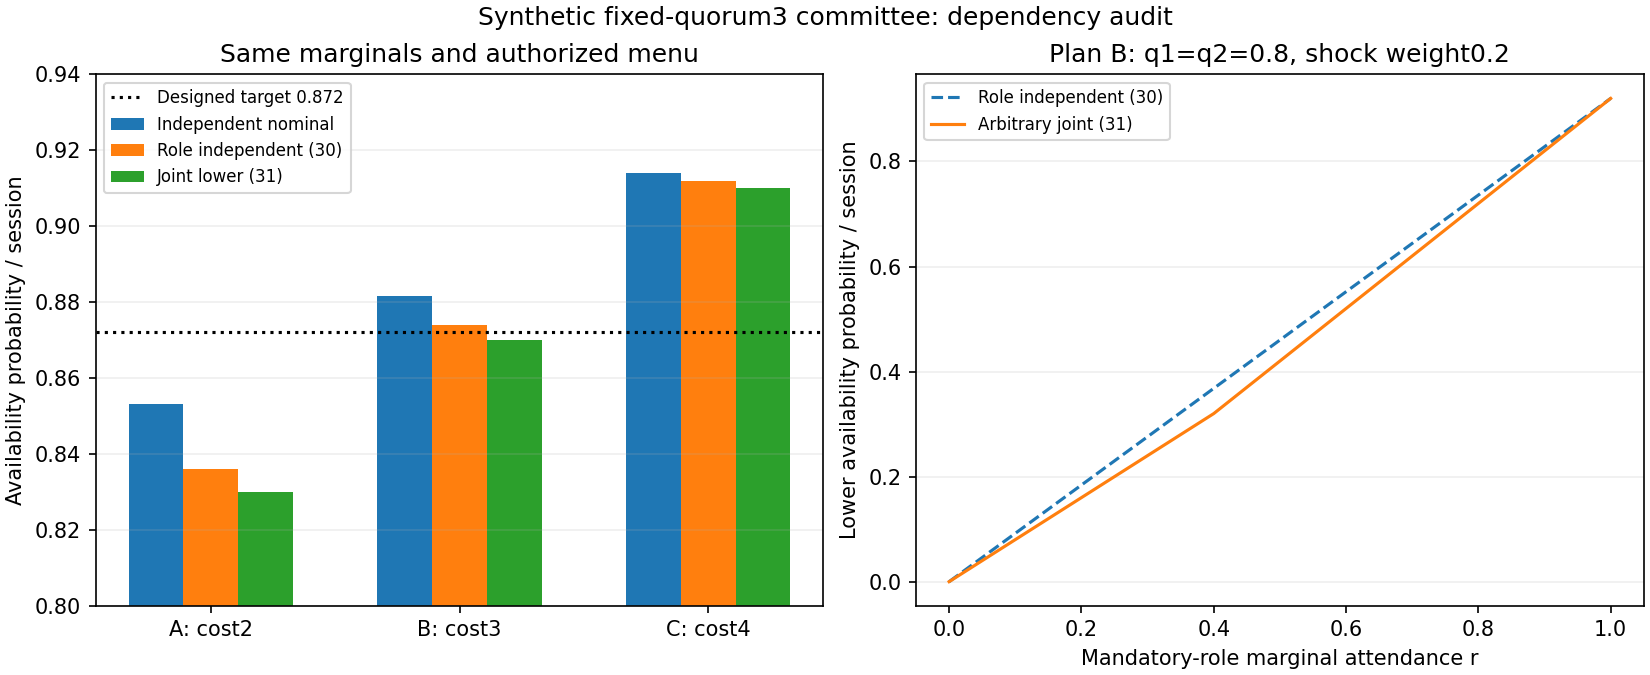

{'closed': 0.00047142900007202115, 'lp8': 0.24370797899996433}

In [9]:
display(pd.read_csv('results/joint_role_decisions.csv'))
assert select_joint(jplans,.85).name=='B'
assert choose_plan(jplans,.872)['name']=='B'
assert select_joint(jplans,.872).name=='C'
display(Image(filename='results/joint_role.png'))
js=json.loads(Path('results/joint_role_summary.json').read_text())
display(js['timings_n100_median_seconds'])

### Falsación, límites y hoja de ruta
Resultados negativos preservados: meta0,85no cambia; meta0,97es imposible porque$P(E)\le r=0,95$; si$r=1$la ampliación no añade protección. Cotas31pueden ser demasiado conservadoras si datos válidos descartan dependencias extremas. Ningún dato estima$r,q,s$ni demuestra que el peor caso ocurra. Tiempo incluye llamadas de cálculo tras warmup y excluye instalación/importación; tracemalloc no mide memoria nativaHiGHS ni RSS. No hay necesidad de semillas porque no usamosMonteCarlo.

Continuar como auditoría sintética y reunir evidencia de asistencias autorizada. Ajustar si el umbral cae en brecha30/31, cuantificando costo adicional. Cerrar la recomendación de menú si no alcanza meta; no bajar quórum. Siguiente hito: intervalos marginales con cobertura estadística, después restricciones empíricas de dependencia. Componente S2 sintético verificado localmente; no programa validado uoperacional. Fuentes ymatriz en referencias.bib/matriz_prior_art.md.